# DALI Data Challenge: Barnacle Counting

**Idea.** Count barnacles inside the inner square of the wire frame with classical computer vision: find whole shells by normalised template matching, count score-map peaks, and rank the detections by score so a person checks the least certain ones first.

**Inputs.** Photographs `img1.png`, `img2.png` with contour-outline masks `mask1.png`, `mask2.png`; unlabelled `unseen_img1.png`, `unseen_img2.png`. Hand-marked inner-frame corners in `data/corners.json`. Agent-verified inner polygons, which exclude the wire and its clips, are in `data/roi_corrected.json` (unseen_img1 review ROI; post-hoc img2 correction).

**Outputs.** Per image: detected barnacle centres (row, col) with a correlation score, a count, and, where masks exist, precision / recall / F1 / count error. For unlabelled images: a review queue and a list of tiles to check first.

**Protocol.** Everything was chosen on img1 (development). Settings were frozen in `data/frozen_params.json` before img2 was scored, and img2 is reported once as a held-out test. The img1 numbers are development results, not independent validation.

Reusable logic is in `src/`; this notebook only calls it. Matching and template tests: `.venv/bin/python -m tests.test_core`.

## 1. Data audit

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import sys; sys.path.insert(0, '.')
import numpy as np
import pandas as pd
import warnings
from src import dataio, viz, truth, region, detect, evaluate as ev, pipeline, review
from src import templates as tm
viz.inline_formats(dpi=72)  # photos inline as JPEG, plots as PNG; keeps the notebook under 10 MB

In [2]:
files = ['img1.png','img2.png','mask1.png','mask2.png','masked_img1.png','masked_img2.png','unseen_img1.png','unseen_img2.png']
pd.DataFrame([dataio.describe(f) for f in files])

,file,shape,dtype,alpha
0,img1.png,"(2448, 3264, 4)",uint8,constant 255
1,img2.png,"(2448, 3264, 3)",uint8,none
2,mask1.png,"(2448, 3264, 4)",uint8,varies (3.9% opaque)
3,mask2.png,"(2448, 3264, 4)",uint8,varies (3.6% opaque)
4,masked_img1.png,"(1453, 1449, 4)",uint8,constant 255
5,masked_img2.png,"(1701, 1691, 4)",uint8,constant 255
6,unseen_img1.png,"(2448, 3264, 3)",uint8,none
7,unseen_img2.png,"(500, 500, 3)",uint8,none


Mask outlines live only in the alpha channel (RGB is white everywhere), so masks are read with `IMREAD_UNCHANGED`. `masked_img*` are cropped to the frame interior and are used for viewing only.

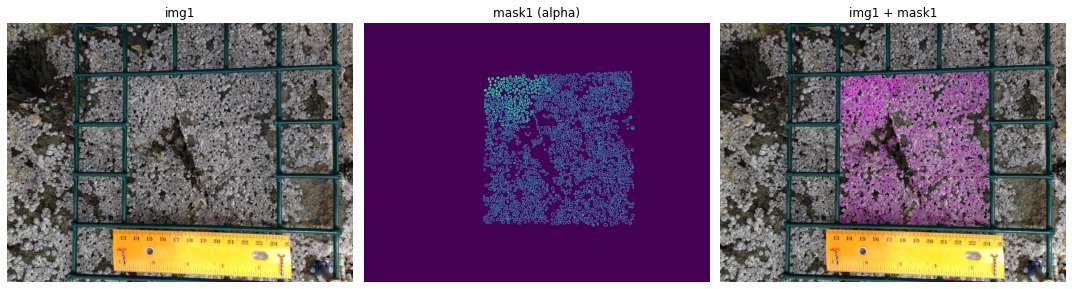

In [3]:
img1, img2 = dataio.load_rgb('img1.png'), dataio.load_rgb('img2.png')
m1 = dataio.load_outline_mask('mask1.png')
viz.show_grid([img1, m1, viz.overlay_outline(img1, m1)], ['img1', 'mask1 (alpha)', 'img1 + mask1']);

## 2. Ground truth from mask1

Binarize the outline lines, fill each closed outline, subtract the lines, and label the remaining interiors with connected components. An interior is one barnacle if its area is ≥ 10 px (smaller ones are gaps inside thick lines).

In [4]:
gt_cents, gt_areas = truth.mask_instances('mask1.png')
gt_diam = truth.equivalent_diameter(gt_areas)
print(f'mask1 barnacles: {len(gt_cents)}')
print(f'equivalent diameter: median {np.median(gt_diam):.1f} px, 5th-95th pct {np.percentile(gt_diam, 5):.1f}-{np.percentile(gt_diam, 95):.1f} px')

mask1 barnacles: 1694
equivalent diameter: median 14.8 px, 5th-95th pct 6.4-25.3 px


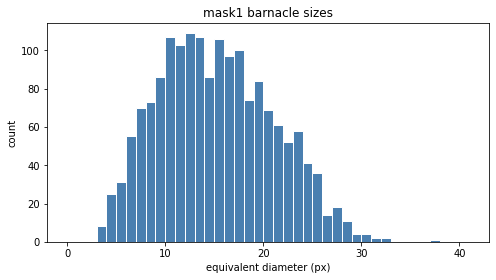

In [5]:
viz.histogram(gt_diam, bins=np.arange(0, 42, 1), xlabel='equivalent diameter (px)', title='mask1 barnacle sizes');

Centroids over img1, with mask outlines in magenta. A merge would show as one centroid between two plates; counted background would show as a centroid on rock or between shells.

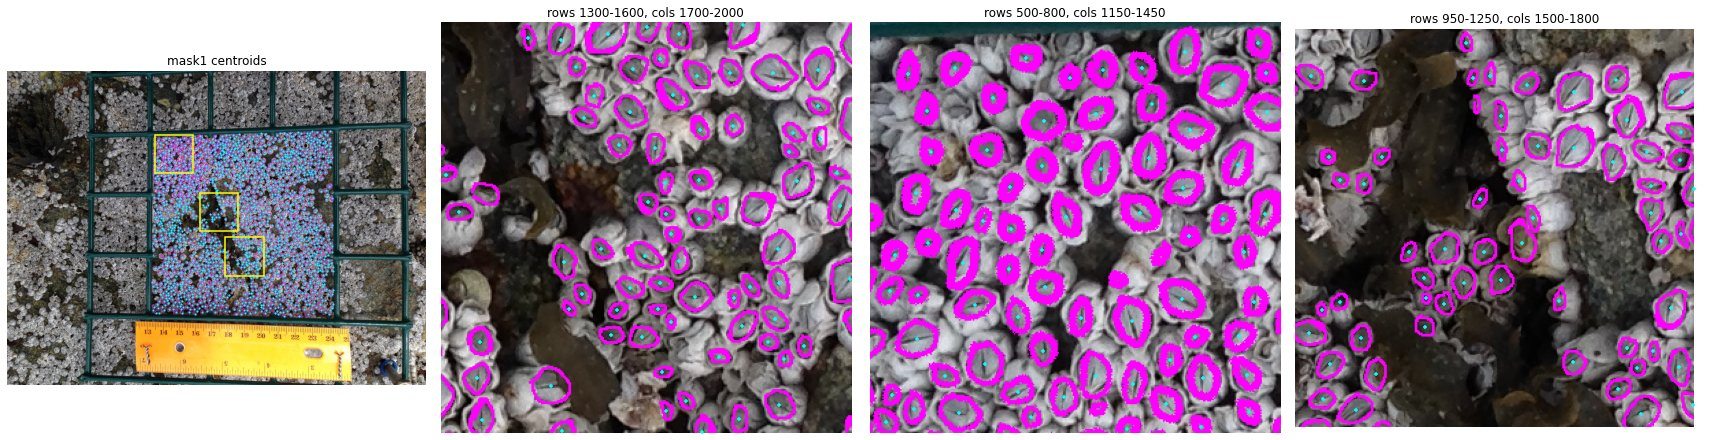

In [6]:
viz.show_points(img1, gt_cents, [(1300, 1700, 300), (500, 1150, 300), (950, 1500, 300)], title='mask1 centroids', outline=m1);

The largest interiors are the most likely merges, so inspect them directly.

largest interiors (px): [1129, 815, 809]


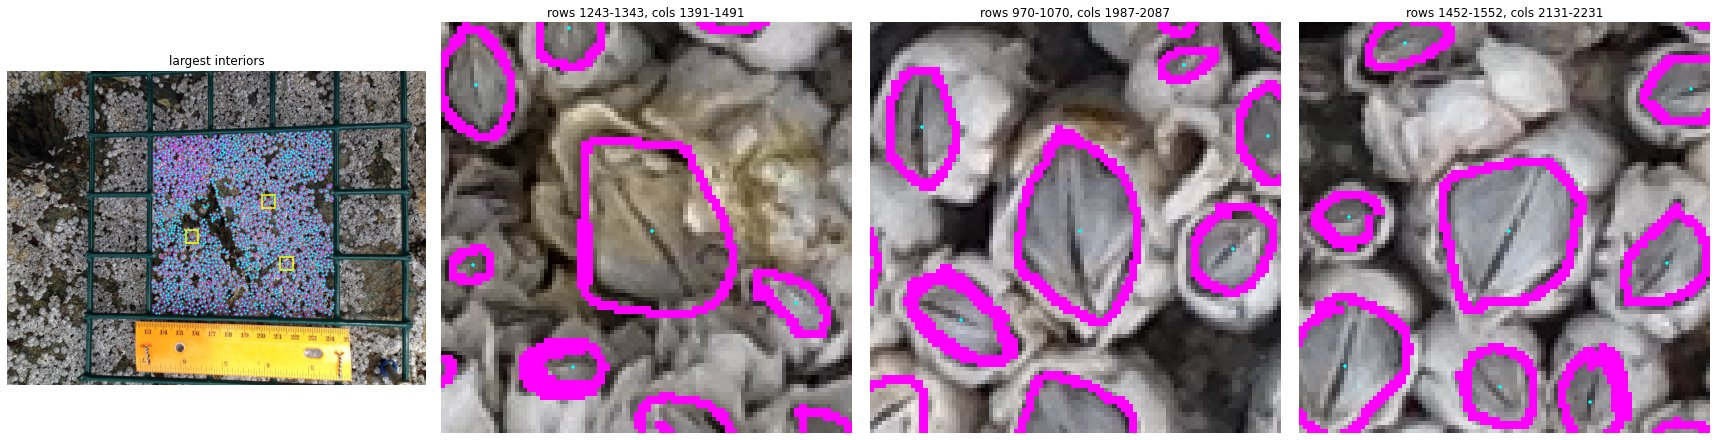

In [7]:
big = np.argsort(gt_areas)[-3:][::-1]
print('largest interiors (px):', gt_areas[big].tolist())
viz.show_points(img1, gt_cents, [(int(r) - 50, int(c) - 50, 100) for r, c in gt_cents[big]], title='largest interiors', outline=m1);

None of the three largest interiors is a merge: each holds one plate. The 815 and 809 px instances are large single barnacles. The 1,129 px instance is a single worn, tan-coloured shell whose appearance differs from the rest; its identity is uncertain, but appearance alone is not reason to override the annotation, so it stays in the ground truth.

Test: does a morphological closing seal the 51 open outlines without damaging closed ones?

In [8]:
pd.DataFrame([truth.compare_closing(m1, k) for k in [3, 5, 7, 9]])

,ksize,holes,change,open_outlines_closed,recovered_holes,spurious_new_holes,merged_holes,lost_holes,max_hole_area
0,3,1697,3,13/51,13,0,0,11,1128
1,5,1639,-55,17/51,17,15,0,87,1124
2,7,1545,-149,18/51,18,65,0,232,1122
3,9,1400,-294,17/51,17,146,0,457,1619


Closing never merged holes, but it filled small real holes (all 11 lost at k=3 were 10–19 px) and, at larger kernels, sealed background gaps between neighbours into artificial holes. Ground truth therefore uses plain option A at 10 px, without closing: **1,694 barnacles in mask1**.

**Ground-truth limitations**
- Inspection identified 22 additional barnacles missed by the outline-based method (open or line-filled outlines 13–33 px across), approximately 1.3% of the resulting estimated total of 1,716. This is the measured shortfall from the inspected outlines, not an estimate of all annotation omissions.
- Completely unoutlined barnacles remain unquantified, so some detections scored as false positives may be correct.

## 3. Evaluation region

The four inner corners of the frame are marked by hand per image (`data/corners.json`; re-mark with `python -m src.region img1.png`). The same polygon filters both ground-truth and detected centroids before matching.

img1 uses these hand-marked corners throughout. The polygons for img2 (a post-hoc correction) and unseen_img1 (the operational review ROI) are agent-verified and stored in `data/roi_corrected.json`; sections 8.2 and 10 describe them.

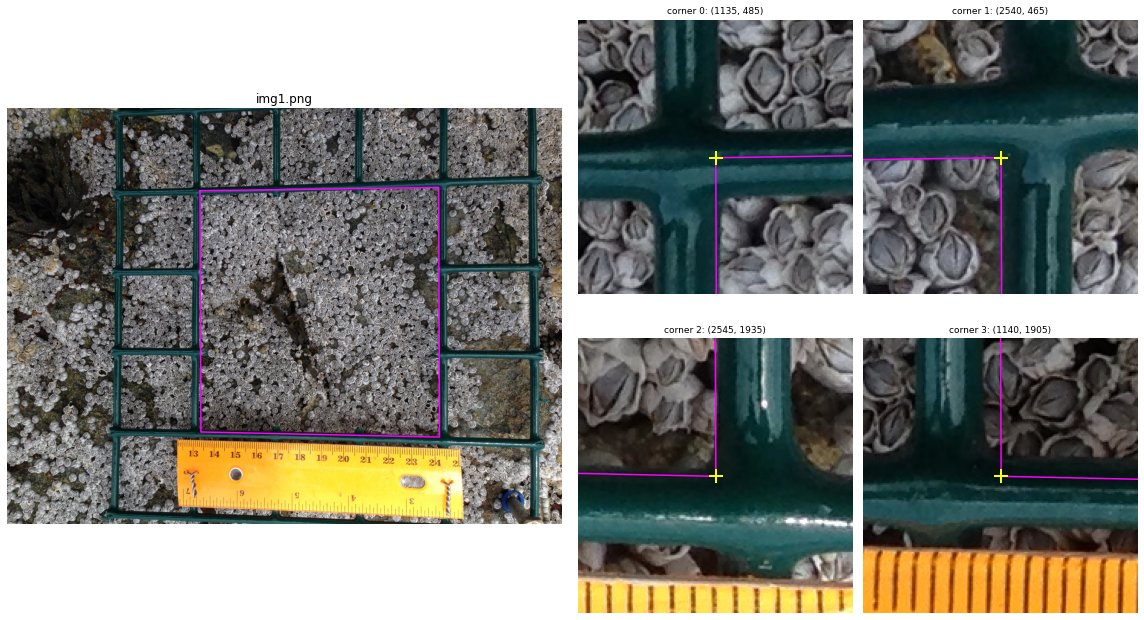

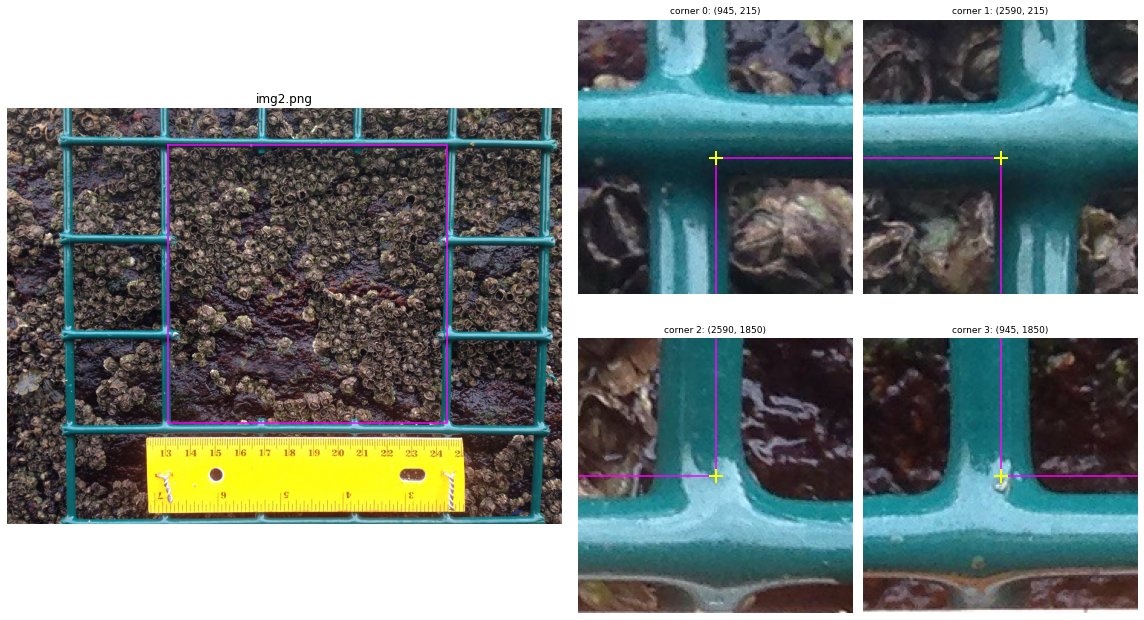

In [9]:
corners1 = region.load_corners('img1.png')
viz.show_region(img1, corners1, 'img1.png')
viz.show_region(img2, region.load_corners('img2.png'), 'img2.png');

In [10]:
gt_in = region.inside(gt_cents, corners1)
gt_eval, gt_eval_diam = gt_cents[gt_in], gt_diam[gt_in]
print(f'mask1: {len(gt_cents)} total, {gt_in.sum()} inside the img1 polygon')

mask1: 1694 total, 1689 inside the img1 polygon


## 4. How results are scored, and why

A detection is a point; a ground-truth barnacle is the centroid of an outlined plate. They are paired **one-to-one** within a radius:

- **Radius** = 0.5 × median equivalent plate diameter of the img1 ground truth inside the ROI, in original pixels. Half a typical plate means a detection must land on the plate, not on a neighbour. It is computed once from img1 and frozen for every image.
- **Gate inside the assignment.** Only pairs within the radius are allowed; among allowed pairings the one with the most pairs wins, then the smallest total distance. Running unrestricted Hungarian assignment and discarding far pairs afterwards can lose valid pairs (a counterexample is in `tests/test_core.py`).
- **Metrics.** Count error tells whether the total is right; precision and recall tell whether it is right for the right reasons (a detector can hit the count with half its points on rock). F1 summarises both.

Coordinates are (row, col) everywhere in `src`; only the corner files store (x, y).

In [11]:
gt_areas_eval = gt_areas[gt_in]
radius = ev.match_radius(gt_areas_eval)
print(f'match radius: {radius:.2f} px (0.5 x median img1 plate diameter {np.median(gt_eval_diam):.2f} px)')

match radius: 7.42 px (0.5 x median img1 plate diameter 14.84 px)


In [12]:
import tests.test_core as T
for name in [n for n in dir(T) if n.startswith('test_')]:
    getattr(T, name)()
print('all matching / template / suppression tests passed')

all matching / template / suppression tests passed


## 5. First detector: Laplacian-of-Gaussian on inverted greyscale (rejected)

Premise tested: the annotated plates are dark spots, so on the inverted greyscale they become bright blobs. Sigma 3.5–9 (d ≈ 2√2·σ ≈ 10–25 px, the plate size range); `threshold=0.2` and `overlap=0.5` are blob_log's library defaults. Detection runs on the whole image; centres are then filtered by the frame polygon. Nothing was tuned.

In [13]:
det = detect.detect(img1, corners1)
det_rc = np.c_[det['rows'], det['cols']]
print(f"{len(det_rc)} detections inside the polygon vs {len(gt_eval)} ground-truth barnacles")

960 detections inside the polygon vs 1689 ground-truth barnacles


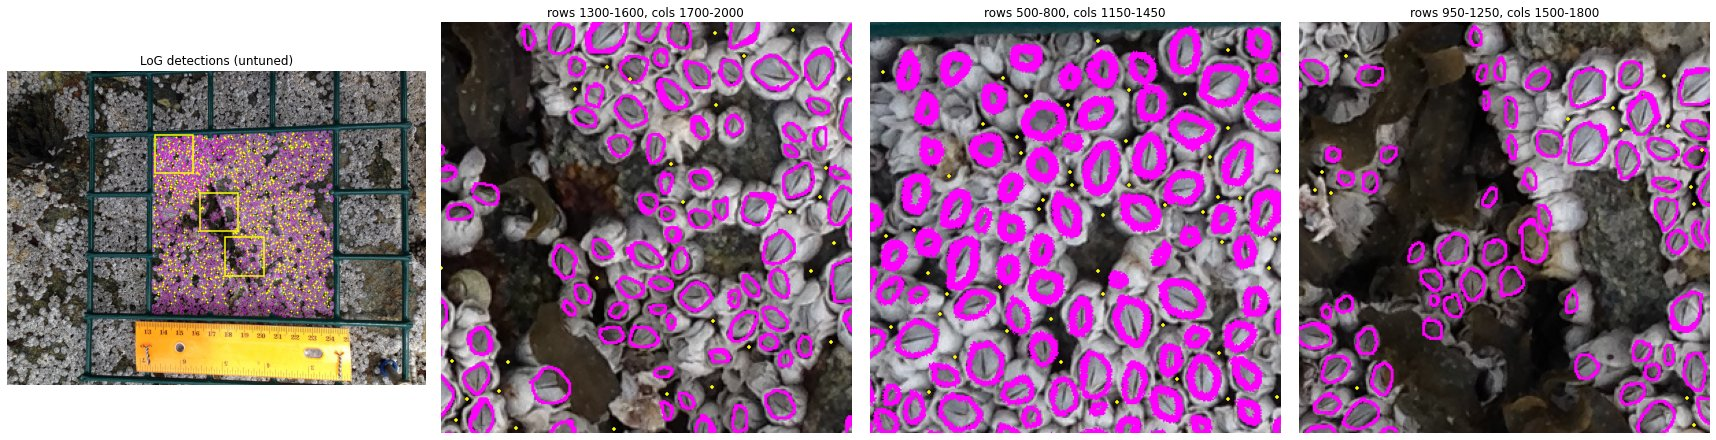

In [14]:
viz.show_points(img1, det_rc, [(1300, 1700, 300), (500, 1150, 300), (950, 1500, 300)], title='LoG detections (untuned)', color='yellow', outline=m1);

In [15]:
frac, n_on = detect.fraction_on_plates(det['rows'], det['cols'], 'mask1.png')
g1 = 1 - detect.inverted_gray(img1)
gt_rc = gt_eval.astype(int)
print(f'detections inside an annotated plate: {n_on} of {len(det_rc)} ({frac:.2%})')
print(f"median grey level (0 = black, 1 = white): detections {np.median(g1[det['rows'], det['cols']]):.2f}, plate centres {np.median(g1[gt_rc[:, 0], gt_rc[:, 1]]):.2f}")

detections inside an annotated plate: 5 of 960 (0.52%)
median grey level (0 = black, 1 = white): detections 0.08, plate centres 0.42


The premise was wrong. In img1 a barnacle is a **bright white shell surrounding a mid-grey plate**; the darkest spots are the crevices between shells. The inverted-LoG detector therefore selects crevices: less than 1% of its detections fall inside an annotated plate. This is the evidence for switching to whole-shell template matching.

## 6. Template matching on whole shells

### 6.1 Whole-shell size

Templates must contain the whole shell, not just the plate. Shell diameter is estimated from the radial brightness profile around each annotated plate centre: outward from the plate edge, brightness peaks on the white shell and falls toward the gap; the shell edge is where it drops halfway.

In [16]:
g1f = tm.gray(img1)
shell_d = tm.shell_diameters(g1f, gt_eval, gt_eval_diam)
ok = np.isfinite(shell_d)
print(f'measurable shell edge: {ok.sum()} of {len(shell_d)}')
pd.DataFrame({'plate diameter (px)': np.percentile(gt_eval_diam[ok], [10, 50, 90]), 'shell diameter (px)': np.percentile(shell_d[ok], [10, 50, 90]), 'shell / plate': np.percentile(shell_d[ok] / gt_eval_diam[ok], [10, 50, 90])}, index=['10th pct', 'median', '90th pct']).round(1)

measurable shell edge: 1679 of 1689


,plate diameter (px),shell diameter (px),shell / plate
10th pct,7.7,22.0,1.6
median,14.8,34.0,2.1
90th pct,23.5,46.0,3.9


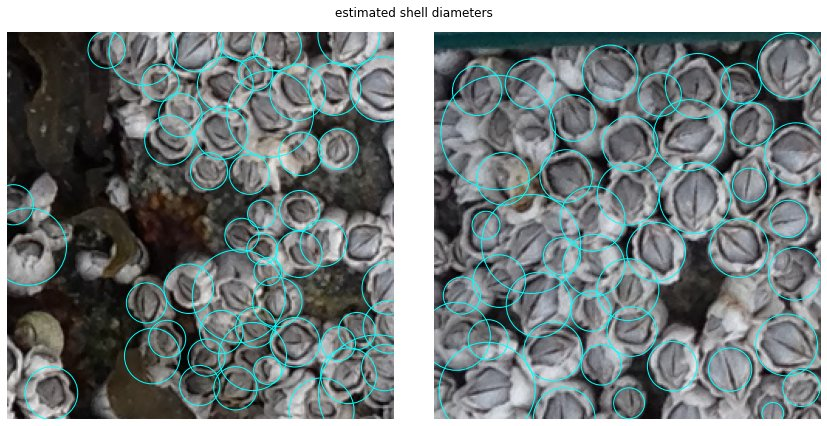

In [17]:
viz.show_circles(img1, gt_eval, shell_d, [(1300, 1700, 250), (500, 1150, 250)], title='estimated shell diameters');

Most circles fit their shell. Oversized circles occur where packed shells touch and brightness never drops between them, which inflates the upper tail; the median is the reliable figure.

Paired measurements: does the wall get thicker relative to the shell as shells get smaller?

In [18]:
from scipy.stats import spearmanr
wall = (shell_d[ok] - gt_eval_diam[ok]) / 2
print(f'Spearman, plate diameter vs shell/plate ratio: {spearmanr(gt_eval_diam[ok], shell_d[ok] / gt_eval_diam[ok])[0]:.2f}')
print(f'Spearman, plate diameter vs wall width (px):   {spearmanr(gt_eval_diam[ok], wall)[0]:.2f}, median wall {np.median(wall):.1f} px')

Spearman, plate diameter vs shell/plate ratio: -0.73
Spearman, plate diameter vs wall width (px):   -0.02, median wall 8.5 px


The ratio falls with plate size, but the absolute wall width is roughly constant (~8.5 px) across sizes, so small shells have proportionally thicker walls only because a fixed width is a larger share of a small shell. Part of that constant may come from the measurement itself (blur and the half-drop rule can set a floor on measured width).

### 6.2 Template candidates

Size groups by estimated shell diameter: ~25, ~33 and ~41 px (±3 px). A barnacle is eligible if exactly one annotated plate centroid lies inside its shell circle. Each crop is the group size plus a 4 px margin on each side, enlarged when the shell is larger, and centred on the plate centroid. 40 candidates per group are drawn at random with a fixed seed; `n` under each crop is the share of crop pixels belonging to other annotated plates.

Selection criteria for choosing 2–3 per group: one annotated plate, a visible whole shell, limited neighbouring material. Templates are chosen by appearance against these criteria, not by evaluation score.

In [19]:
import cv2
from scipy import ndimage as ndi
gt_ids = np.arange(len(gt_cents))[gt_in]
_, interior_lab = cv2.connectedComponents((ndi.binary_fill_holes(m1) & ~m1).astype(np.uint8), connectivity=4)
eligible = tm.candidate_table(g1f, gt_eval, gt_eval_diam, shell_d, interior_lab, gt_ids)
cands = tm.sample_candidates(eligible)
print('eligible per group:', pd.Series([r['group'] for r in eligible]).value_counts().sort_index().to_dict())
print('crop sides used:', {k: sorted({c['side'] for c in cands if c['group'] == k}) for k in (25, 33, 41)})

eligible per group: {25: 439, 33: 531, 41: 338}
crop sides used: {25: [33, 35, 37], 33: [41, 43, 45], 41: [49, 51, 53]}


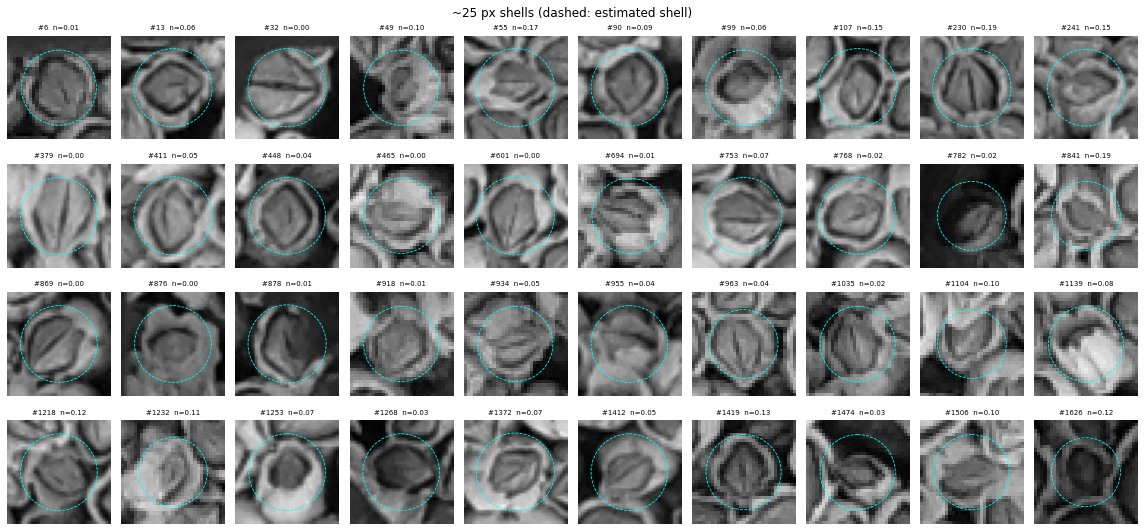

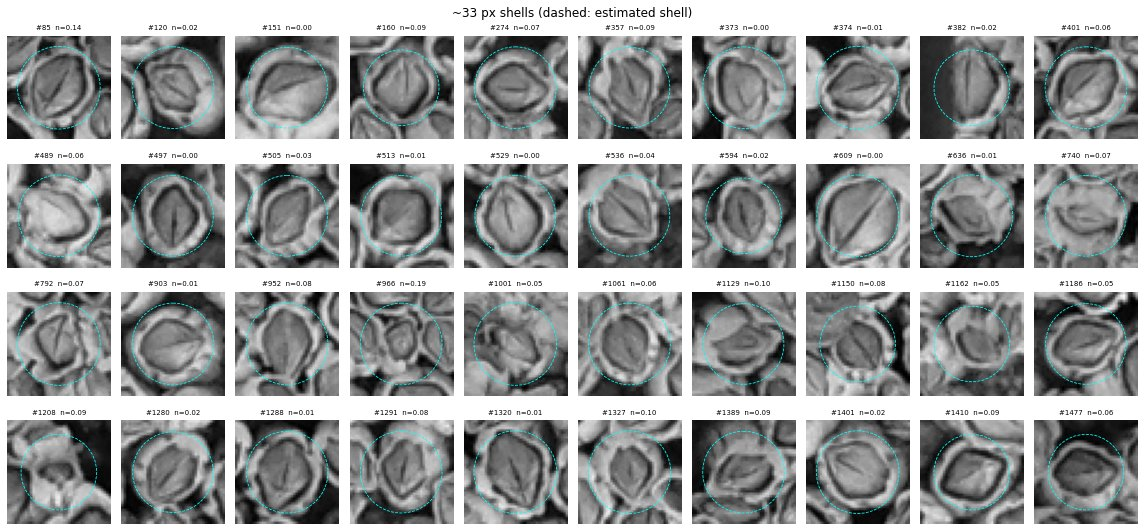

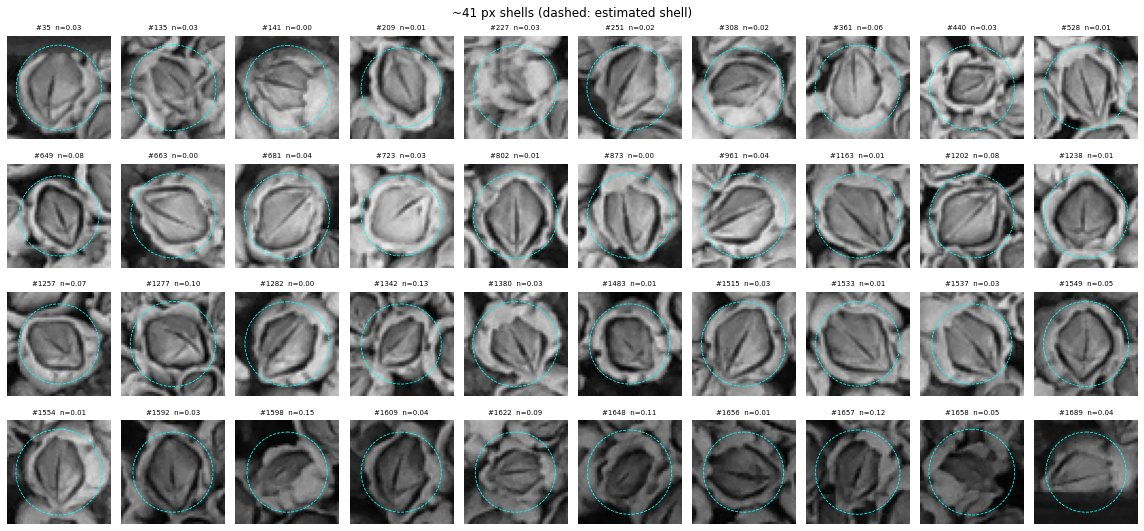

In [20]:
for k in (25, 33, 41):
    fig = viz.show_gallery(g1f, [c for c in cands if c['group'] == k], tm.crop)
    fig.suptitle(f'~{k} px shells (dashed: estimated shell)', y=1.01)
    fig.savefig(f'figures/gallery_{k}.png', dpi=110, bbox_inches='tight')

### 6.3 Rotation: does a shell look the same turned 180°?

If it did, rotations 0°–135° would cover every orientation. Check: correlation of each shell with its own rotation, inside its shell circle only (so neighbours don't interfere), against two unrelated shells, at several blur levels.

In [21]:
rows = []
for sb in (0, 1, 2):
    g = ndi.gaussian_filter(g1f, sb) if sb else g1f
    for k in (25, 33, 41):
        r = tm.rotation_check(g, [c for c in cands if c['group'] == k], angles=(90, 180))
        rows.append({'blur sigma': sb, 'group (px)': k, 'self, 90°': r[90], 'self, 180°': r[180], 'unrelated shell': r['unrelated']})
pd.DataFrame(rows).round(2)

,blur sigma,group (px),"self, 90°","self, 180°",unrelated shell
0,0,25,-0.01,-0.13,0.08
1,0,33,0.00,-0.06,-0.01
2,0,41,0.01,0.06,-0.00
3,1,25,-0.02,-0.27,0.08
4,1,33,0.00,-0.09,-0.02
5,1,41,0.03,0.03,-0.00
6,2,25,-0.04,-0.44,0.14
7,2,33,-0.03,-0.19,-0.06
8,2,41,0.05,-0.09,0.02


A shell turned 180° correlates with itself no better than with an unrelated shell, so there is no usable 180° symmetry. Templates are therefore used at **eight rotations** (0°, 45°, …, 315°).

### 6.4 Chosen templates

Nine templates, three per size group, picked by eye from the galleries above for a visible whole shell, a single centred annotated plate and little neighbouring material. Detector scores were not used. All 120 gallery candidates and the reasons for each chosen ID are kept in `data/templates.json`.

,id,group,side,neighbour_frac,appearance_note_claude
0,6,25,33,0.012,"small shell, closed plate slit visible; lower ..."
1,120,33,43,0.021,"medium shell, complete ring, neighbours touch ..."
2,497,33,41,0.002,"medium shell, elongated plate, high-contrast ring"
3,601,25,37,0.001,"small shell, plate centred, shell ring complete"
4,663,41,49,0.000,"large shell, wide wall, no other plates in crop"
5,802,41,49,0.009,"large shell, clear central slit, complete ring"
6,903,33,43,0.007,"medium shell, complete bright ring, plate centred"
7,918,25,33,0.012,"small shell, plate centred, slightly blurred"
8,1282,41,49,0.000,"large shell, plate slightly tilted, no other p..."


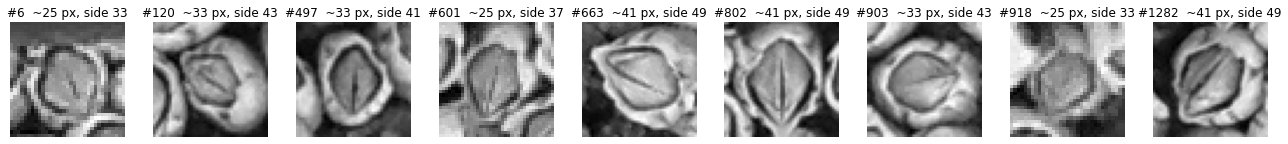

In [22]:
sel = tm.load_selection()
by_id = {c['id']: c for c in sel['candidates']}
crops = [tm.crop(g1f, (by_id[i]['row'], by_id[i]['col']), by_id[i]['side']) for i in sel['chosen_ids']]
viz.show_grid(crops, [f"#{i}  ~{by_id[i]['group']} px, side {by_id[i]['side']}" for i in sel['chosen_ids']], ncols=9, size=2, cmap='gray')
pd.DataFrame(sel['chosen'])[['id', 'group', 'side', 'neighbour_frac', 'appearance_note_claude']]

### 6.5 Rotating a template correctly

Two details decide whether a rotated template still points at the shell centre:

- **Rotation centre.** An odd crop of side 2h+1 has its centre pixel at index h, i.e. ((w−1)/2, (h−1)/2). Rotating about (w/2, h/2) instead moves the centre by half a pixel diagonally at every angle.
- **Corners.** Turning a square by 45° needs pixels that were never in the crop; reflected borders would invent them. Each rotated template is therefore scored only over its inscribed disc (masked `TM_CCOEFF_NORMED`), which rotation maps onto itself, so all eight rotations compare the same real pixels.

Left to right: a template, its 45° rotation with reflected corners (the invented part is outside the circle), and the disc actually compared.

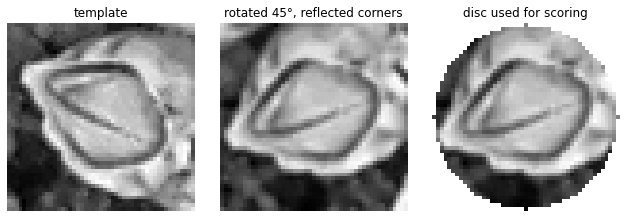

In [23]:
t = crops[4]
v45, disc = tm.variants(t, angles=(45,))[0]
viz.show_grid([t, v45, np.where(disc > 0, v45, np.nan)], ['template', 'rotated 45°, reflected corners', 'disc used for scoring'], ncols=3, size=3, cmap='gray');

## 7. Development tuning on img1

The score map holds, at every pixel, the best masked correlation over all 72 template variants (9 templates × 8 rotations), placed at the template centre. Detections are its local maxima inside the ROI. The map is set to −1 outside the ROI first, so a peak just outside the frame can never suppress one just inside.

Two settings matter:

- **threshold**: minimum correlation for a peak. Correlation ranges from −1 to 1. It is a similarity score used for ranking, **not a calibrated probability** that the point is a barnacle.
- **min_distance**: peaks closer than this (pixels, along rows or columns) are merged into the stronger one. One barnacle can produce peaks from several templates and rotations, so the pixelwise maximum alone does not guarantee one detection per barnacle.

A small grid is searched on img1 and the best F1 is taken. The first grid's optimum sat on its edge (min_distance 12, threshold 0.30), so it was extended once; the optimum stayed at the same place. The settings were then frozen.

In [24]:
fz = pipeline.load_frozen()
roi1 = region.roi_mask(img1.shape, corners1)
sm1 = tm.score_map(g1f, pipeline.frozen_variants(fz))
print('score at each exemplar centre:', {i: round(float(sm1[int(round(by_id[i]['row'])), int(round(by_id[i]['col']))]), 3) for i in sel['chosen_ids']})
print(f'median score: at img1 GT centroids {np.median(sm1[gt_rc[:, 0], gt_rc[:, 1]]):.2f}, over all ROI pixels {np.median(sm1[roi1]):.2f}')

score at each exemplar centre: {6: 1.0, 120: 1.0, 497: 1.0, 601: 1.0, 663: 1.0, 802: 1.0, 903: 1.0, 918: 1.0, 1282: 1.0}
median score: at img1 GT centroids 0.32, over all ROI pixels 0.28


Every exemplar scores 1.0 at its own centre pixel, which confirms the centre placement. The median score on true plates is only slightly above the ROI background, so the correlation separates barnacles weakly.

In [25]:
grid = []
for md in (4, 6, 8, 10, 12, 14, 16, 18):
    for th in (0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60):
        pk, _ = tm.find_peaks(sm1, roi1, md, th)
        m, _ = ev.evaluate(pk, gt_eval, radius)
        grid.append({'min_distance': md, 'threshold': th, **{k: m[k] for k in ('predicted', 'signed count error %', 'precision', 'recall', 'F1')}})
grid = pd.DataFrame(grid)
print(f"frozen: min_distance={fz['min_distance']}, threshold={fz['threshold']}, radius={fz['match_radius_px']:.2f} px")
grid.pivot(index='min_distance', columns='threshold', values='F1').round(3)

frozen: min_distance=12, threshold=0.3, radius=7.42 px


threshold,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60
min_distance,,,,,,,,,
4,0.221,0.224,0.239,0.270,0.307,0.296,0.190,0.078,0.036
6,0.325,0.325,0.330,0.339,0.348,0.307,0.191,0.078,0.036
8,0.390,0.390,0.390,0.389,0.369,0.314,0.190,0.079,0.036
10,0.421,0.421,0.421,0.417,0.384,0.315,0.186,0.078,0.036
12,0.429,0.429,0.429,0.423,0.393,0.320,0.186,0.078,0.036
14,0.424,0.424,0.424,0.420,0.394,0.319,0.186,0.078,0.036
16,0.410,0.410,0.410,0.407,0.389,0.313,0.184,0.078,0.036
18,0.392,0.392,0.392,0.389,0.377,0.309,0.183,0.078,0.036


In [26]:
grid.sort_values('F1', ascending=False).head(8).round(3)

,min_distance,threshold,predicted,signed count error %,precision,recall,F1
36,12,0.20,2071,22.617,0.390,0.478,0.429
38,12,0.30,2071,22.617,0.390,0.478,0.429
37,12,0.25,2071,22.617,0.390,0.478,0.429
47,14,0.30,1686,-0.178,0.425,0.424,0.424
45,14,0.20,1686,-0.178,0.425,0.424,0.424
46,14,0.25,1686,-0.178,0.425,0.424,0.424
39,12,0.35,2038,20.663,0.387,0.467,0.423
29,10,0.30,2686,59.029,0.343,0.546,0.421


At min_distance ≥ 12, every local maximum already scores above 0.30, so thresholds of 0.20–0.30 give identical results: the **count is set mostly by peak spacing**, and the threshold mainly controls how much of the score ranking is kept. min_distance trades recall (small spacing, many duplicate peaks) against precision (large spacing merges neighbours).

Three representative thresholds at the frozen spacing, on the same img1 crop (white dots: GT centroids):

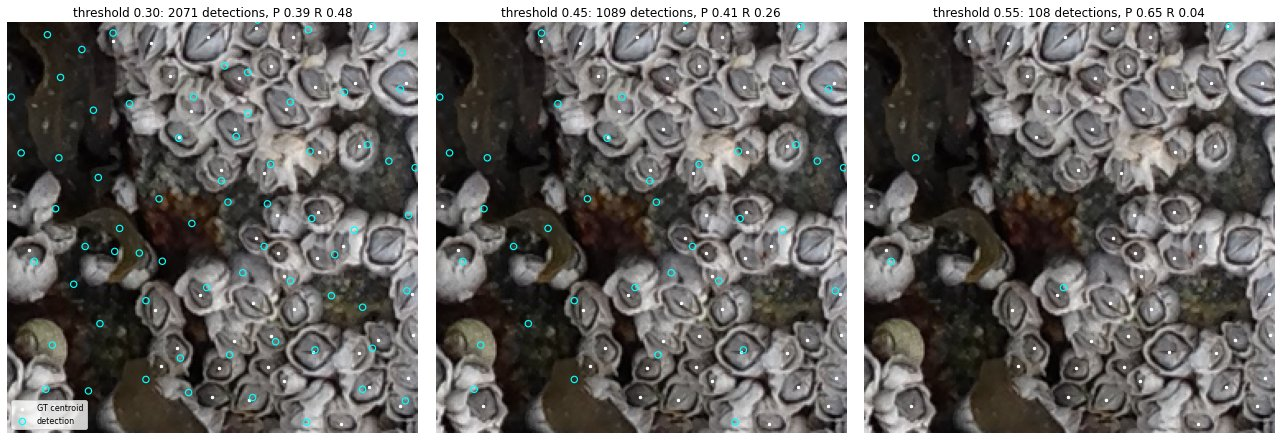

In [27]:
crop = (1300, 1700, 250)
res = []
for th in (0.30, 0.45, 0.55):
    pk, _ = tm.find_peaks(sm1, roi1, fz['min_distance'], th)
    m, _ = ev.evaluate(pk, gt_eval, radius)
    res.append((f"threshold {th:.2f}: {len(pk)} detections, P {m['precision']:.2f} R {m['recall']:.2f}", pk))
viz.show_thresholds(img1, res, crop, gt_rc=gt_eval);

At 0.30 roughly half the shells get a point, and many points fall on rock, algae and shell walls between plates. Raising the threshold removes points from shells and background at similar rates until about 0.55, where the survivors are mostly on shells but almost none remain. No threshold separates the two cleanly, which is why spacing, not threshold, ended up setting the count.

## 8. Frozen results

### 8.1 img1 (development)

In [28]:
r1 = pipeline.run('img1.png', corners1, frozen=fz, score_map=sm1)
m1_dev, (p1, g1_idx, _) = ev.evaluate(r1['peaks'], gt_eval, fz['match_radius_px'])
base1 = ev.random_baseline(roi1, len(r1['peaks']), gt_eval, fz['match_radius_px'])
ex_ids = np.searchsorted(gt_ids, sel['chosen_ids'])
assert (gt_ids[ex_ids] == sel['chosen_ids']).all()
m1_ex, n_drop = ev.evaluate_excluding(r1['peaks'], gt_eval, fz['match_radius_px'], ex_ids)
print(f'exemplar exclusion removed {len(ex_ids)} GT and {n_drop} detections on them')
pd.DataFrame({'img1 full ROI (development)': m1_dev, 'img1 excluding 9 template exemplars': m1_ex,
              'uniform random points, same count': base1}).T.round(3)

exemplar exclusion removed 9 GT and 9 detections on them


,predicted,ground truth,signed count error %,TP,FP,FN,precision,recall,F1
img1 full ROI (development),2071.0,1689.0,22.617,807.0,1264.0,882.0,0.390,0.478,0.429
img1 excluding 9 template exemplars,2062.0,1680.0,22.738,798.0,1264.0,882.0,0.387,0.475,0.427
"uniform random points, same count",2071.0,1689.0,22.617,257.0,1814.0,1432.0,0.124,0.152,0.137


**Exemplar exclusion protocol.** The nine template barnacles score 1.0 against themselves, so they are guaranteed hits. To remove them fairly: match everything first; then drop each exemplar GT together with the detection matched to it, plus any unmatched detection within the radius of an exemplar; report on what remains. (Simply deleting the exemplar GT would turn their detections into false positives.) The main result remains the full-ROI row. With 9 of 1,689 barnacles removed the change is small, as expected.

The random-point row is a floor: a detector that placed points blindly at the same density would score this.

### 8.2 img2 (held-out test, frozen settings)

Run once with `data/frozen_params.json`; nothing below fed back into any setting.

In [29]:
img2 = dataio.load_rgb('img2.png')
corners2 = region.load_corners('img2.png')
gt2_all, gt2_areas = truth.mask_instances('mask2.png')
gt2_in = region.inside(gt2_all, corners2)
gt2 = gt2_all[gt2_in]
r2 = pipeline.run('img2.png', corners2, frozen=fz)
m2, (p2, g2_idx, _) = ev.evaluate(r2['peaks'], gt2, fz['match_radius_px'])
base2 = ev.random_baseline(r2['roi'], len(r2['peaks']), gt2, fz['match_radius_px'])
print(f'mask2: {len(gt2_all)} instances, {gt2_in.sum()} inside the img2 polygon')
results = pd.DataFrame({'img1 development (full ROI)': m1_dev, 'img2 test (frozen)': m2, 'img2 uniform random, same count': base2}).T
results.round(3)

mask2: 396 instances, 396 inside the img2 polygon


,predicted,ground truth,signed count error %,TP,FP,FN,precision,recall,F1
img1 development (full ROI),2071.0,1689.0,22.617,807.0,1264.0,882.0,0.390,0.478,0.429
img2 test (frozen),2850.0,396.0,619.697,130.0,2720.0,266.0,0.046,0.328,0.080
"img2 uniform random, same count",2850.0,396.0,619.697,67.0,2783.0,329.0,0.024,0.169,0.041


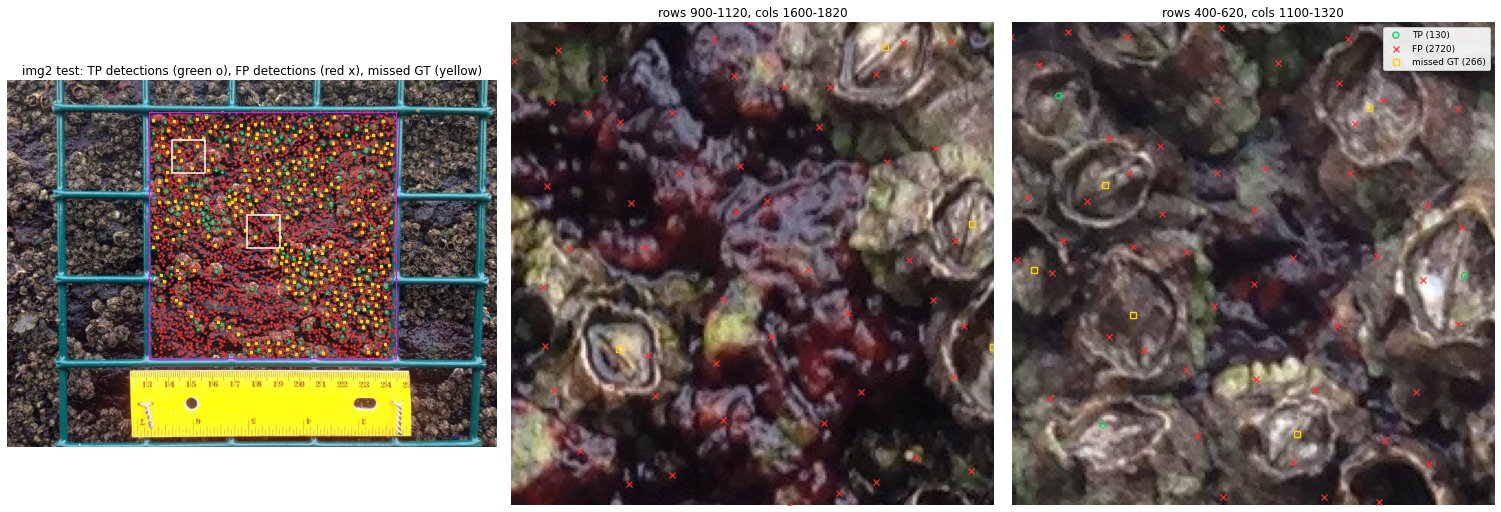

In [30]:
viz.match_overlay(img2, r2['peaks'], gt2, p2, g2_idx, corners2, crops=[(900, 1600, 220), (400, 1100, 220)],
                  title='img2 test: TP detections (green o), FP detections (red x), missed GT (yellow)');

**img2 is a different scene.** mask2 has 396 outlined barnacles against 1,689 in img1, with a median plate area of 404 px against 173 px: img2 holds fewer, larger, brown plated shells on dark red algae, while img1 is packed with small white shells. The frozen detector, built from nine img1 shells, places points at roughly its fixed spacing across the whole frame (2,850 detections), so the count is far too high and only about a third of the img2 barnacles are found. It still beats random points of the same density (F1 0.080 vs 0.041), but it does not transfer. This is the held-out result; no setting was changed in response.

**ROI caveat found while inspecting failures.** The img2 corners in `data/corners.json` lie on the centreline of the wire rather than its inner edge: up to ~38 px of the right bar and ~8–20 px of the left bar fall inside the polygon, and the highest-scoring img2 false positives are on that wire (section 8.3). Two post-hoc ROI rows follow. Neither replaces the held-out result above, which stays the result of record.
1. **Historical sensitivity row:** inner-edge corners re-read by eye earlier (`data/corners_provisional.json`).
2. **Post-hoc ROI correction:** the agent-verified inner polygon in `data/roi_corrected.json`. Codex picked the starting quadrilateral and checked its corners on 200 px zooms. Claude moved the top edge down 7 px and the bottom edge up 5 px (they touched the wire's shaded underside and its rounded fillets) and cut notches around the eight teal clips and tabs that stick into the opening. Claude then checked every corner, notch and edge on zooms; the four-corner view is below and all views are saved as `figures/roi_img2_*.png`. Only visible frame geometry was used. The ROI was not checked by the user and is not exact.

The detector, templates, threshold, peak spacing and match radius are the frozen img1 values. `data/frozen_params.json` is unchanged, and nothing was re-tuned.

verification figures: figures/roi_img2_whole.png, figures/roi_img2_corners.png, figures/roi_img2_notches.png, figures/roi_img2_edges.png


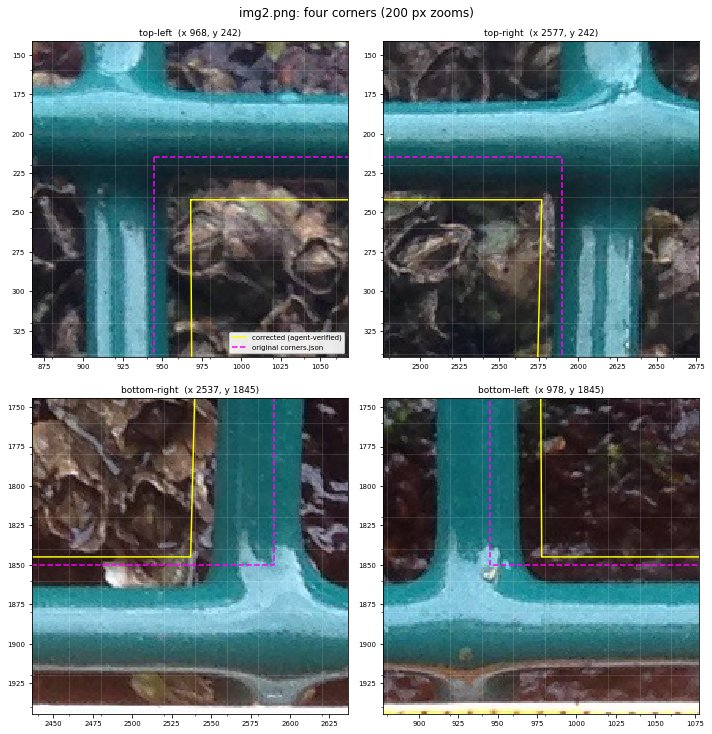

In [31]:
fix2 = region.load_corrected('img2.png')
paths2 = viz.roi_figures(img2, {'corrected (agent-verified)': region.load_corrected_polygon('img2.png'),
                                'original corners.json': corners2}, fix2, 'img2', 'figures')
print('verification figures:', ', '.join(paths2.values()))

In [32]:
corners2_inner = region.load_provisional_corners('img2.png')
gt2_s = gt2_all[region.inside(gt2_all, corners2_inner)]
r2s = pipeline.run('img2.png', corners2_inner, frozen=fz, score_map=r2['score_map'])
m2s, _ = ev.evaluate(r2s['peaks'], gt2_s, fz['match_radius_px'])
corners2_fix = region.load_corrected_polygon('img2.png')
gt2_f = gt2_all[region.inside(gt2_all, corners2_fix)]
r2f = pipeline.run('img2.png', corners2_fix, frozen=fz, score_map=r2['score_map'])
m2f, (p2f, g2f_idx, _) = ev.evaluate(r2f['peaks'], gt2_f, fz['match_radius_px'])
base2f = ev.random_baseline(r2f['roi'], len(r2f['peaks']), gt2_f, fz['match_radius_px'])
print(f"ROI area: corners.json {r2['roi'].sum():,} px, corrected {r2f['roi'].sum():,} px")
pd.DataFrame({'img2 test (frozen, corners.json) - result of record': m2,
              'img2 sensitivity: eye-read inner-edge ROI (post hoc, historical)': m2s,
              'img2 post-hoc ROI correction (agent-verified polygon, no retuning)': m2f,
              'img2 uniform random in corrected ROI, same count': base2f}).T.round(3)

ROI area: corners.json 2,691,210 px, corrected 2,520,581 px


,predicted,ground truth,signed count error %,TP,FP,FN,precision,recall,F1
"img2 test (frozen, corners.json) - result of record",2850.0,396.0,619.697,130.0,2720.0,266.0,0.046,0.328,0.080
"img2 sensitivity: eye-read inner-edge ROI (post hoc, historical)",2854.0,396.0,620.707,128.0,2726.0,268.0,0.045,0.323,0.079
"img2 post-hoc ROI correction (agent-verified polygon, no retuning)",2712.0,395.0,586.582,129.0,2583.0,266.0,0.048,0.327,0.083
"img2 uniform random in corrected ROI, same count",2712.0,395.0,586.582,75.0,2637.0,320.0,0.028,0.190,0.048


Neither ROI change alters the conclusion about img2.

- **Earlier eye-read ROI:** F1 0.079.
- **Agent-verified correction:** F1 0.083 (precision 0.048, recall 0.327). It excludes the wire, the eight clips and tabs, and a thin strip beside the wire, which shrinks the ROI by 6 % (2.69 M to 2.52 M px). That removes 138 detections (2,850 to 2,712) and one ground-truth centroid (396 to 395).
- **Random points** at the same density in the corrected ROI: F1 0.048.

The wire accounted for some of the strongest false positives but only a small share of the count, so removing it barely moves the metrics. The change in barnacle appearance, not the ROI, explains the poor img2 result.

**Labelling.** The `corners.json` row stays the held-out test result of record. The corrected row is a **post-hoc ROI correction**: it was made after seeing img2 results, using frame geometry only, with the detector and `data/frozen_params.json` unchanged.

### 8.3 Failure cases (img2)

Highest-scoring false positives and a sample of misses, each 61 px wide and centred on the point.

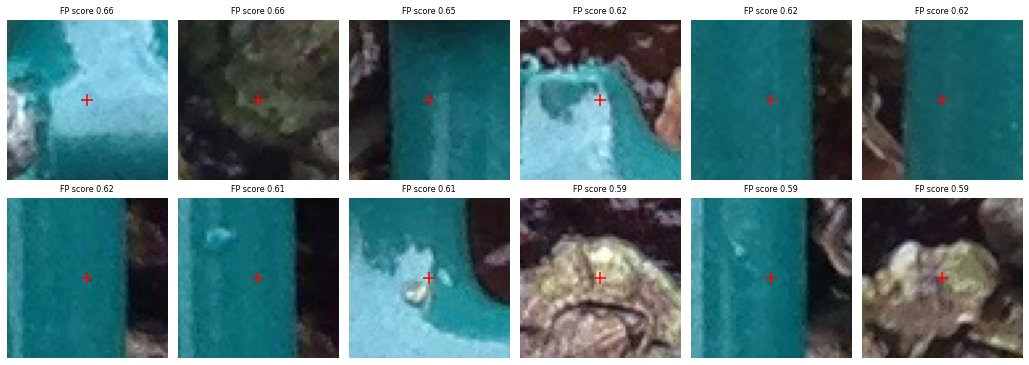

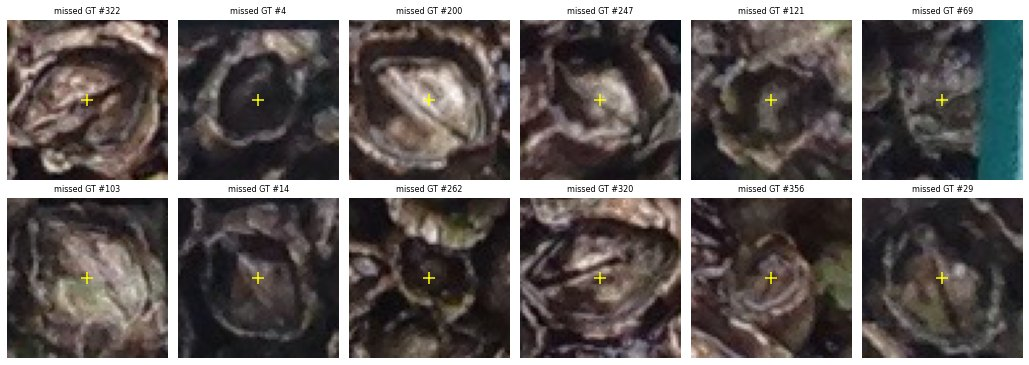

In [33]:
tp2 = np.zeros(len(r2['peaks']), bool); tp2[p2] = True
fp_pts, fp_sc = r2['peaks'][~tp2], r2['scores'][~tp2]
viz.show_patches(r2['rgb'], fp_pts[:12], [f'FP score {s:.2f}' for s in fp_sc[:12]], mark='red')
fn2 = np.setdiff1d(np.arange(len(gt2)), g2_idx)
pick = np.random.default_rng(0).choice(fn2, 12, replace=False)
viz.show_patches(r2['rgb'], gt2[pick], [f'missed GT #{i}' for i in pick], mark='yellow');

What these show:
- **The top-scoring false positives are mostly teal frame wire** inside the stored polygon, plus pale lichen-like patches. Flat bright regions with one edge correlate well with a bright shell ring on one side. A strong score is therefore not evidence of a barnacle on this image.
- **The misses are large, dark-plated img2 shells**, wider than any img1 template and with brown rather than white walls; none resembles an img1 exemplar closely.
- Most of the 2,720 false positives are points on algae and rock placed at the 12 px peak spacing (overlay above).
- Annotation limits from section 2 still apply: some unmatched points may sit on barnacles that were never outlined, so measured precision can understate true precision, by an unknown amount. Matching uses plate centroids, so a point on a shell wall more than 7.4 px from the plate centre counts as a false positive even if it is on the right barnacle.
- With the post-hoc corrected polygon (section 8.2), the wire and clips are outside the ROI. None of the 12 highest-scoring false positives below is centred on wire. They fall on green algae, rock or lichen, and on pale shell fragments or crowded shells; some of these may be unoutlined barnacles (section 2). One is 1 px inside the top edge, but it is centred on a shell just below the wire.

distance of the 12 highest-scoring FPs to the corrected ROI edge (px): [59, 466, 67, 168, 262, 261, 175, 1, 317, 69, 347, 711]


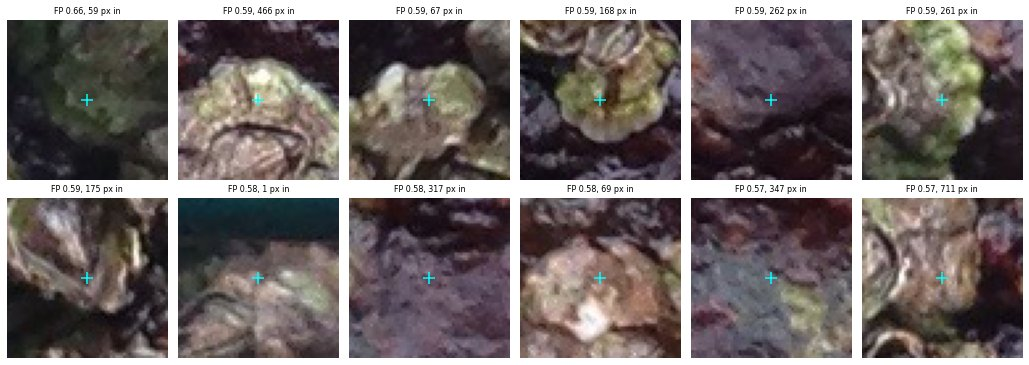

In [34]:
# top false positives under the post-hoc corrected img2 polygon (display only; nothing is tuned from this)
tp2f = np.zeros(len(r2f['peaks']), bool); tp2f[p2f] = True
fpf, fpf_sc = r2f['peaks'][~tp2f][:12], r2f['scores'][~tp2f][:12]
dist = region.distance_to_edge(fpf, corners2_fix)
print('distance of the 12 highest-scoring FPs to the corrected ROI edge (px):', dist.round(0).astype(int).tolist())
viz.show_patches(r2f['rgb'], fpf, [f'FP {s:.2f}, {d:.0f} px in' for s, d in zip(fpf_sc, dist)]);

## 9. Confidence and human review

### 9.1 Is a higher score more trustworthy?

Accept detections from the highest score down. At each prefix the accepted set is re-matched one-to-one against all GT from scratch, so cumulative precision is exact for that prefix. These are empirical tradeoffs on these two images; they do not guarantee the precision of automatically accepted detections on new images, and even a perfect top-score set leaves the barnacles the detector never found.

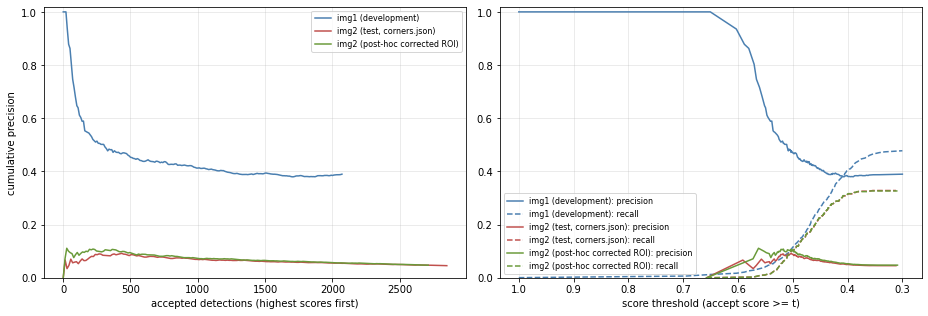

In [35]:
c1 = ev.precision_curve(r1['peaks'], r1['scores'], gt_eval, fz['match_radius_px'])
c2 = ev.precision_curve(r2['peaks'], r2['scores'], gt2, fz['match_radius_px'])
c2f = ev.precision_curve(r2f['peaks'], r2f['scores'], gt2_f, fz['match_radius_px'])
viz.precision_curves({'img1 (development)': c1, 'img2 (test, corners.json)': c2, 'img2 (post-hoc corrected ROI)': c2f}); 

In [36]:
def at_k(c, k):
    i = np.searchsorted(c['k'], k)
    return {'accepted': int(c['k'][i]), 'score >=': round(float(c['threshold'][i]), 3), 'precision': round(float(c['precision'][i]), 3), 'recall': round(float(c['recall'][i]), 3)}
pd.DataFrame([{'image': lbl, **at_k(c, k)} for lbl, c in (('img1', c1), ('img2', c2), ('img2 post-hoc corrected ROI', c2f)) for k in (50, 200, 500, 1000, int(c['k'][-1]))])

,image,accepted,score >=,precision,recall
0,img1,51,0.580,0.863,0.026
1,img1,201,0.528,0.537,0.064
2,img1,501,0.491,0.453,0.134
3,img1,1001,0.455,0.413,0.245
4,img1,2071,0.300,0.390,0.478
5,img2,57,0.557,0.070,0.010
6,img2,211,0.525,0.081,0.043
7,img2,505,0.497,0.087,0.111
8,img2,1009,0.467,0.068,0.174
9,img2,2850,0.312,0.046,0.328


On img1 the very top of the ranking is fairly reliable (precision 0.86 for the first 50 detections) but falls to about 0.45 by 500 and then flattens: past the first few hundred, a higher score barely means a more likely barnacle. On img2 precision stays at 0.05–0.09 at every prefix, and with the `corners.json` ROI the very top is worse than the middle because wire scores highest. With the post-hoc corrected ROI the wire is gone: precision is 0.09–0.11 for the first 500 accepted detections and falls to 0.048 over all 2,712. That is still far below img1, so on img2 the score carries little signal. The score can order a review queue on images like img1; it does not justify auto-accepting detections, and it says nothing about the barnacles that were never detected.

**Low-confidence criterion (fixed on img1).** A detection is *low confidence* if its score is below **0.50**. On img1, detections at or above 0.50 (the top fifth) matched GT at 0.47, versus 0.33–0.41 in each lower score band, so below 0.50 the score carries little signal.

In [37]:
bands = lambda r, p: pd.Series(np.isin(np.arange(len(r['peaks'])), p)).groupby(pd.cut(r['scores'], [0.3, 0.4, 0.45, 0.5, 0.55, 1.0]), observed=True).agg(['mean', 'size'])
pd.concat({'img1 matched share': bands(r1, p1), 'img2 matched share': bands(r2, p2)}, axis=1).round(3)

img1 matched share      img2 matched share      
                          mean size               mean  size
(0.3, 0.4]               0.433  289              0.016   372
(0.4, 0.45]              0.343  693              0.032  1078
(0.45, 0.5]              0.368  676              0.051   936
(0.5, 0.55]              0.410  305              0.094   392
(0.55, 1.0]              0.638  105              0.056    72

### 9.2 Where to look first

The ROI's bounding box is cut into a 5 × 5 grid. Each tile reports how many detections it holds and what share of them is low confidence; pixels outside the frame polygon are ignored (dimmed). Tiles with no detections have an **undefined** share and are listed as *empty*, not as good. Tiles with fewer than 5 detections or under 25 % of their area inside the ROI are not ranked. The six eligible tiles with the highest low-confidence share are shown.

This ranks where detections most need checking. It does **not** estimate where barnacles were missed. The `matched_to_GT` column is shown for context on labelled images and is not used for ranking.

Because most detections score below 0.50, every img1 tile is 67–91 % low confidence. The ranking separates tiles only weakly and says which tiles to open first, not that the other tiles are fine.

,tile,roi_frac,detections,low_conf,low_share,status,matched_to_GT
4,r0c4,0.98,93,85,0.91,eligible,39
2,r0c2,0.97,88,78,0.89,eligible,35
13,r2c3,1.00,83,71,0.86,eligible,32
10,r2c0,0.99,86,73,0.85,eligible,38
21,r4c1,0.93,79,67,0.85,eligible,31
17,r3c2,1.00,84,69,0.82,eligible,31


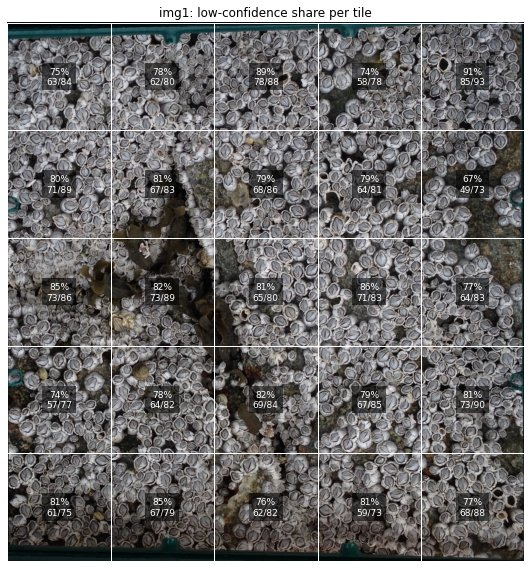

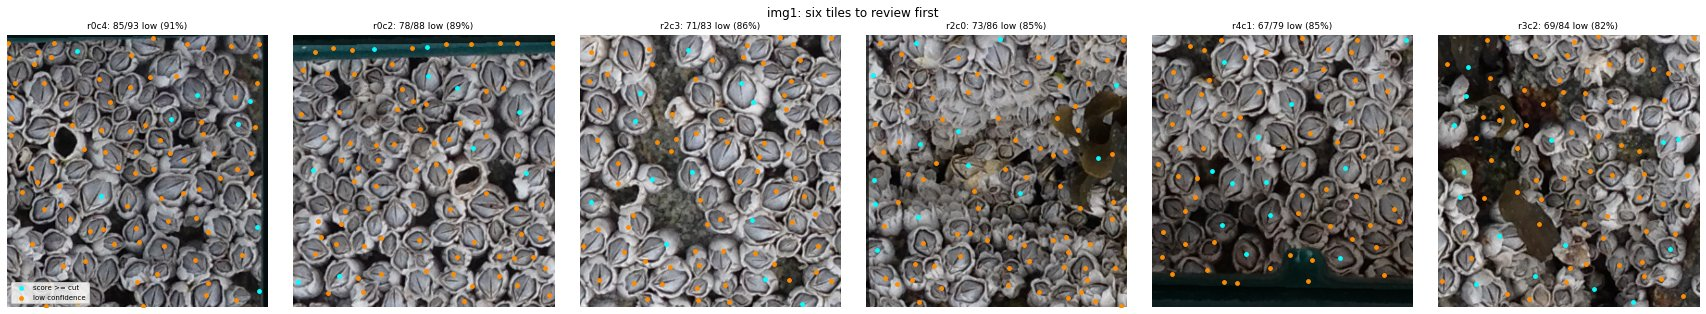

In [38]:
tp1 = np.isin(np.arange(len(r1['peaks'])), p1)
t1 = review.tile_table(r1['peaks'], r1['low'], r1['roi'], fz['tile_grid'], fz['tile_min_roi_frac'], fz['tile_min_detections'], tp=tp1)
viz.tile_grid(r1['rgb'], t1, r1['roi'], 'img1: low-confidence share per tile')
w1 = review.worst_tiles(t1)
viz.show_tiles(r1['rgb'], w1, r1['peaks'], r1['low'], r1['roi'], 'img1: six tiles to review first')
w1.drop(columns=['row0', 'row1', 'col0', 'col1']).round(2)

tile status counts: {'eligible': 25}


,tile,roi_frac,detections,low_conf,low_share,status,matched_to_GT
18,r3c3,1.0,114,107,0.94,eligible,9
8,r1c3,1.0,110,100,0.91,eligible,6
22,r4c2,1.0,125,113,0.90,eligible,4
20,r4c0,1.0,129,115,0.89,eligible,1
2,r0c2,1.0,115,102,0.89,eligible,9
17,r3c2,1.0,114,101,0.89,eligible,1


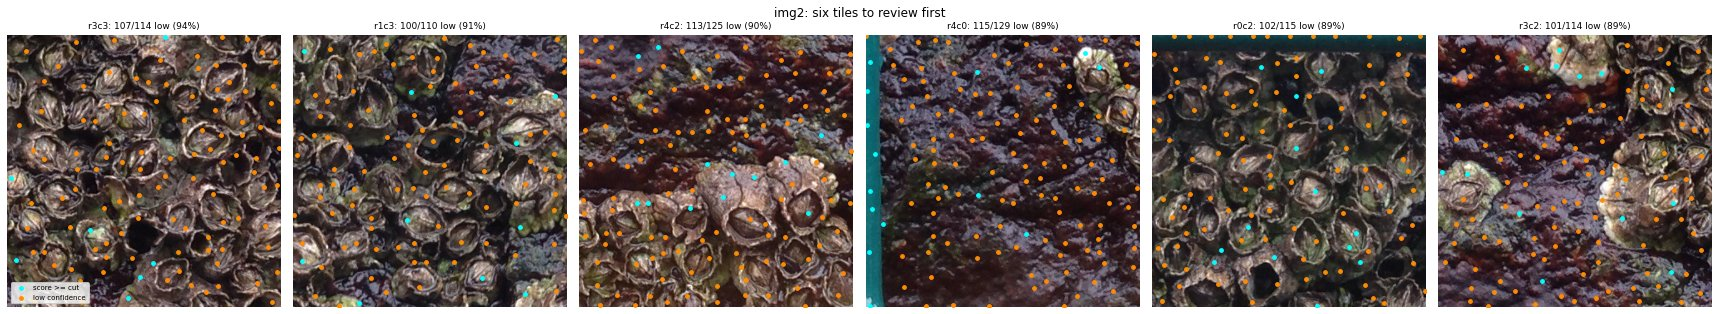

In [39]:
t2 = review.tile_table(r2['peaks'], r2['low'], r2['roi'], fz['tile_grid'], fz['tile_min_roi_frac'], fz['tile_min_detections'], tp=tp2)
w2 = review.worst_tiles(t2)
viz.show_tiles(r2['rgb'], w2, r2['peaks'], r2['low'], r2['roi'], 'img2: six tiles to review first')
print('tile status counts:', t2.status.value_counts().to_dict())
w2.drop(columns=['row0', 'row1', 'col0', 'col1']).round(2)

## 10. Unseen image: frozen pipeline and review queue

`unseen_img1.png` has no mask and no entry in `data/corners.json`. Its review ROI is the **agent-verified inner polygon** in `data/roi_corrected.json`. Codex picked the starting quadrilateral and checked its corners on 200 px zooms. Claude then cut eight rectangular notches around the teal clips and tabs that stick into the opening (two per side, found by `region.wire_intrusions` and padded by 8 px). Claude checked every corner, notch and edge on zooms; the four-corner view is below, and all views are saved as `figures/roi_unseen_img1_{whole,corners,notches,edges}.png`. No coordinate was chosen from detector output or scores.

What the ROI is not: it was not checked by the user and it is not exact. To stay off the wire it sits about 4–15 px inside the visible wire edge (tightest about 3–5 px, at the left edge and next to one ring clip), so a thin strip of barnacles beside the wire and around each clip is left out. The earlier eye-read quadrilateral (`data/corners_provisional.json`) touched the wire at the rounded junctions and included the clips. It is kept only as a historical comparison.

The frame opening here is about 11 % wider in pixels than in img1 (1,557 vs 1,405 px), so shells are slightly larger than the templates. No rescaling was added, because that would be a choice made on unlabelled data. The scene resembles img1 (packed pale shells), not img2.

verification figures: figures/roi_unseen_img1_whole.png, figures/roi_unseen_img1_corners.png, figures/roi_unseen_img1_notches.png, figures/roi_unseen_img1_edges.png
unseen_img1: 2150 detections in the agent-verified ROI, 1299 low confidence (60%); 2197 in the earlier eye-read ROI


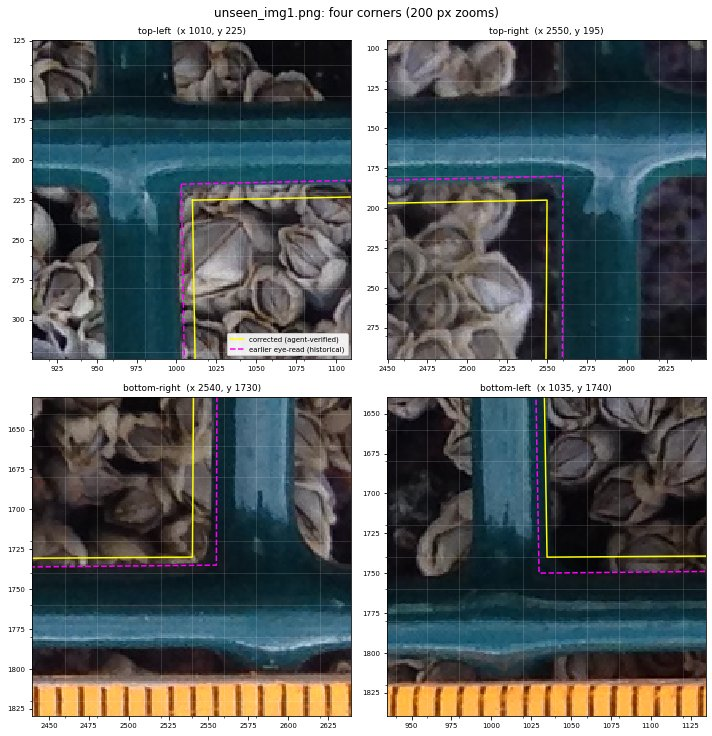

In [40]:
corners_u = region.load_corrected_polygon('unseen_img1.png')
fix_u = region.load_corrected('unseen_img1.png')
corners_u_old = region.load_provisional_corners('unseen_img1.png')
ru = pipeline.run('unseen_img1.png', corners_u, frozen=fz)
paths_u = viz.roi_figures(ru['rgb'], {'corrected (agent-verified)': corners_u, 'earlier eye-read (historical)': corners_u_old},
                          fix_u, 'unseen_img1', 'figures')
n_u_old = len(pipeline.run('unseen_img1.png', corners_u_old, frozen=fz, score_map=ru['score_map'])['peaks'])
print('verification figures:', ', '.join(paths_u.values()))
print(f"unseen_img1: {len(ru['peaks'])} detections in the agent-verified ROI, {ru['low'].sum()} low confidence ({ru['low'].mean():.0%}); "
      f"{n_u_old} in the earlier eye-read ROI")

,tile,roi_frac,detections,low_conf,low_share,status
2,r0c2,0.95,92,73,0.79,eligible
16,r3c1,1.00,88,66,0.75,eligible
12,r2c2,1.00,90,65,0.72,eligible
5,r1c0,0.95,93,66,0.71,eligible
11,r2c1,1.00,87,57,0.66,eligible
9,r1c4,0.97,86,56,0.65,eligible


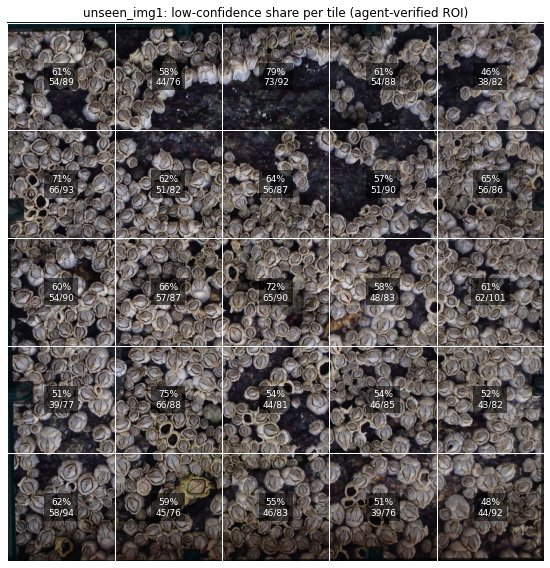

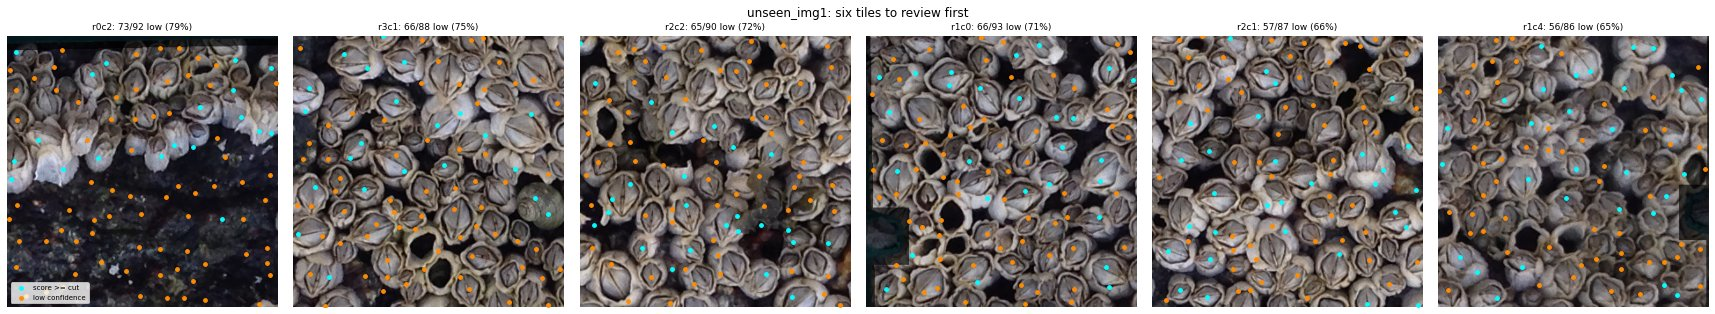

In [41]:
tu = review.tile_table(ru['peaks'], ru['low'], ru['roi'], fz['tile_grid'], fz['tile_min_roi_frac'], fz['tile_min_detections'])
viz.tile_grid(ru['rgb'], tu, ru['roi'], 'unseen_img1: low-confidence share per tile (agent-verified ROI)')
wu = review.worst_tiles(tu)
viz.show_tiles(ru['rgb'], wu, ru['peaks'], ru['low'], ru['roi'], 'unseen_img1: six tiles to review first')
wu.drop(columns=['row0', 'row1', 'col0', 'col1']).round(2)

queue saved to results/unseen_img1_review_queue.csv (2150 detections, least confident first)


,row,col,score,low_conf,dist_to_roi_edge_px
0,210,1800,0.334,True,0.4
1,1245,1253,0.336,True,167.0
2,225,1013,0.341,True,0.1
3,1113,2297,0.342,True,235.3
4,1083,2093,0.349,True,438.0
5,832,1022,0.353,True,2.0
6,1300,1365,0.356,True,279.1
7,459,1558,0.358,True,210.2
8,1131,2402,0.360,True,133.7
9,1636,1053,0.360,True,19.7


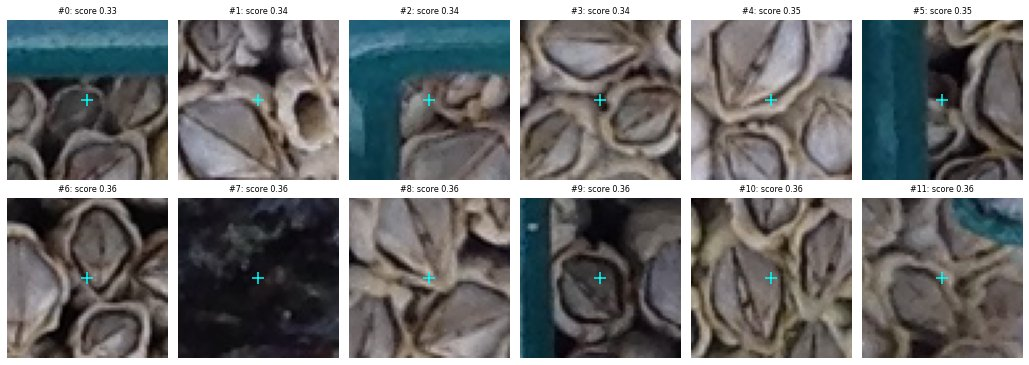

In [42]:
queue = review.review_queue(ru['peaks'], ru['scores'], ru['low'])
queue['dist_to_roi_edge_px'] = region.distance_to_edge(queue[['row', 'col']].values, corners_u).round(1)
queue.to_csv('results/unseen_img1_review_queue.csv', index_label='rank')
viz.show_patches(ru['rgb'], queue[['row', 'col']].values[:12], [f"#{i}: score {s:.2f}" for i, s in enumerate(queue.score[:12])])
print(f"queue saved to results/unseen_img1_review_queue.csv ({len(queue)} detections, least confident first)")
queue.head(15).round(3)

**Reading the queue.** The least-confident items are shell walls between plates, overlapping shells, and dark rock (#7). Items #0, #2 and #5 are 0–2 px inside the ROI edge, and #9 and #11 are near it. Their centres sit on shells beside the wire, not on the wire, but their 61 px patches (and the template windows) overlap the wire, which may be why they score low. The ROI limits where detection centres may lie, not what the template window sees.

A reviewer works down `results/unseen_img1_review_queue.csv` (least confident first, with each item's distance to the ROI edge) and starts with the six tiles above. This ranks detections for checking. It does not estimate missed barnacles, and no acceptance precision is promised on this unlabelled image.

**Out of scope: `unseen_img2.png`.** It is a 500 × 500 close-up with no frame. Its shells are roughly 40–60 px across and look like the img2 type (brown, plated), unlike the img1 shells the templates came from. The frozen templates were cut at img1 scale with `scales=(1.0,)`, and there is no frame to define an ROI, so running the frozen pipeline on it would need new scale and region choices made on unlabelled data. The challenge brief asks only for `unseen_img1.png`, so this image is deliberately left out of scope. That is a scope decision, not a blocker.

## 11. Summary table

In [43]:
summary = results.loc[['img1 development (full ROI)', 'img2 test (frozen)'], ['predicted', 'ground truth', 'signed count error %', 'precision', 'recall', 'F1']].copy()
summary.loc['img2 sensitivity: eye-read inner-edge ROI (post hoc, historical)'] = [m2s[k] for k in summary.columns]
summary.loc['img2 post-hoc ROI correction (agent-verified polygon, no retuning)'] = [m2f[k] for k in summary.columns]
summary.loc['unseen_img1 (agent-verified ROI, no GT)'] = [len(ru['peaks'])] + [np.nan] * 5
summary.loc['unseen_img1 (earlier eye-read ROI, historical, no GT)'] = [n_u_old] + [np.nan] * 5
summary.round(3)

,predicted,ground truth,signed count error %,precision,recall,F1
img1 development (full ROI),2071.0,1689.0,22.617,0.390,0.478,0.429
img2 test (frozen),2850.0,396.0,619.697,0.046,0.328,0.080
"img2 sensitivity: eye-read inner-edge ROI (post hoc, historical)",2854.0,396.0,620.707,0.045,0.323,0.079
"img2 post-hoc ROI correction (agent-verified polygon, no retuning)",2712.0,395.0,586.582,0.048,0.327,0.083
"unseen_img1 (agent-verified ROI, no GT)",2150.0,NaN,NaN,NaN,NaN,NaN
"unseen_img1 (earlier eye-read ROI, historical, no GT)",2197.0,NaN,NaN,NaN,NaN,NaN
